# 작은 YOLO 서비스 노트북

사진을 넣으면 **detection 박스(yolo26n.pt)** 와 **segmentation 마스크(yolo26n-seg.pt)** 를 보여 줍니다.

- 실행 위치: 내 컴퓨터(로컬), CPU (`device=cpu`), `imgsz=640`
- 임계값 `conf=0.25` 와 `conf=0.50` 결과를 나란히 비교
- 결과는 `outputs/yolo/<사진이름>/` 에 저장 (이미지, `result.json`, `mask_label.png`, `manifest.json`)

**위에서부터 한 셀씩 `Shift + Enter` 로 실행하세요.**

## 1. 준비

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image, display, JSON

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import yolo_service as ys
from ultralytics import YOLO

det_model = YOLO(str(ys.DET_WEIGHTS))
seg_model = YOLO(str(ys.SEG_WEIGHTS))
OUT = ROOT / "outputs" / "yolo"
print("detection 클래스 수:", len(det_model.names), "/ 관찰 대상:", ys.WATCH_CLASSES)

detection 클래스 수: 80 / 관찰 대상: ['person', 'bus', 'car', 'bicycle', 'motorcycle', 'truck', 'traffic light', 'stop sign', 'handbag', 'backpack']


## 2. 버스 예제 사진 — conf 0.25 vs 0.50

  [bus] conf0.25: 박스 5개, 마스크 5개


  [bus] conf0.50: 박스 5개, 마스크 5개
{
  "input": "input/bus.jpg",
  "width": 810,
  "height": 1080,
  "runs": {
    "conf0.25": {
      "det_count": 5,
      "seg_count": 5,
      "classes": [
        "bus",
        "person"
      ]
    },
    "conf0.50": {
      "det_count": 5,
      "seg_count": 5,
      "classes": [
        "bus",
        "person"
      ]
    }
  },
  "removed_when_raising_threshold": []
}


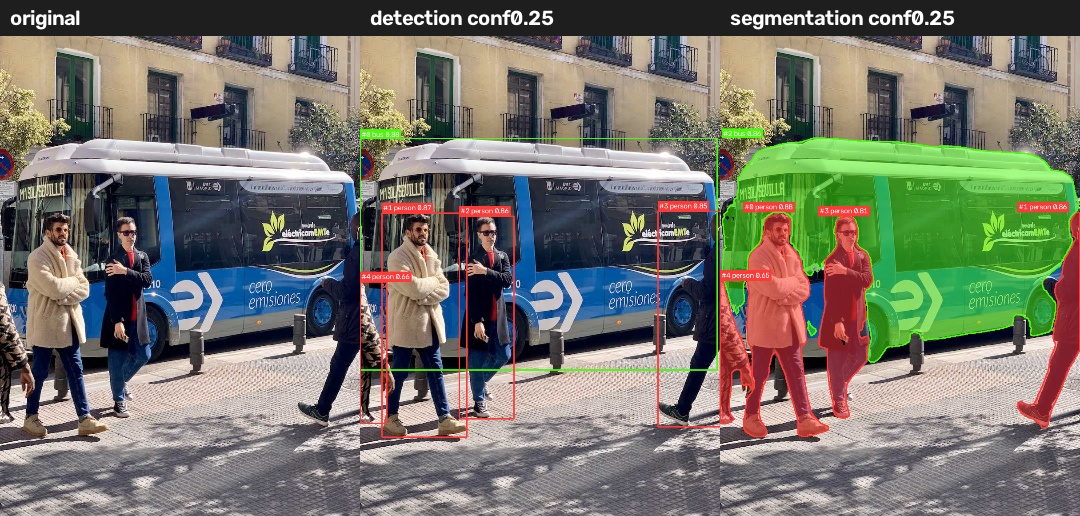

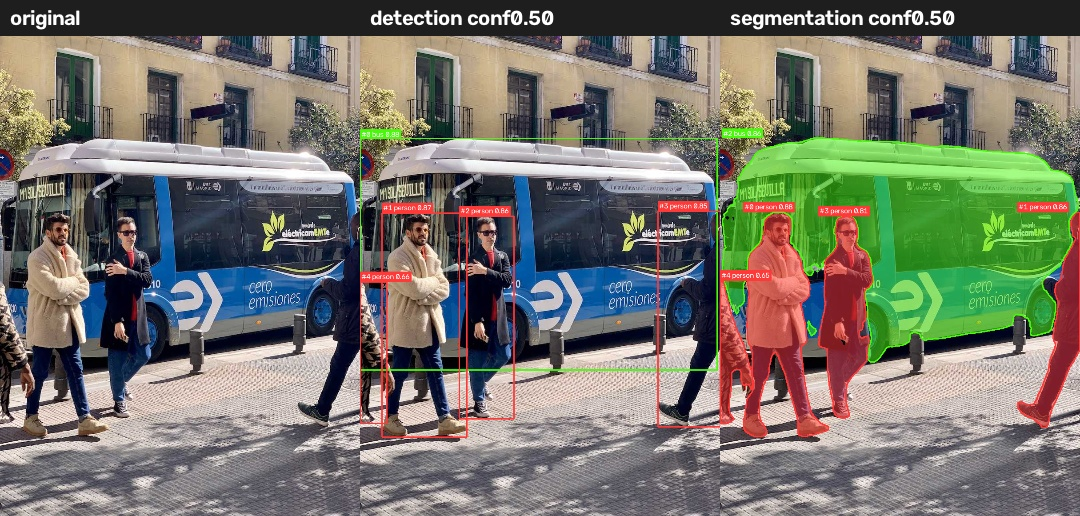

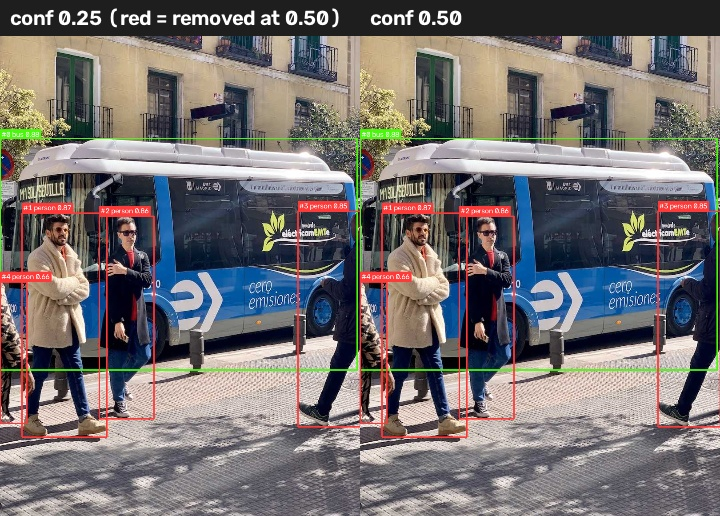

In [2]:
IMG = ROOT / "input" / "bus.jpg"
summary = ys.process_image(IMG, det_model, seg_model, [0.25, 0.50], 640, "cpu", OUT)
print(json.dumps(summary, ensure_ascii=False, indent=2))
d = OUT / IMG.stem
display(Image(str(d / "conf0.25" / "panel.jpg")))
display(Image(str(d / "conf0.50" / "panel.jpg")))
display(Image(str(d / "compare_thresholds.jpg")))

### 박스 하나를 JSON 좌표와 연결해 보기
화면의 `#번호` 와 JSON 의 `id` 가 같은 박스입니다.

In [3]:
res = json.loads((d / "conf0.25" / "result.json").read_text(encoding="utf-8"))
for b in res["detection"]["boxes"]:
    print(f'#{b["id"]:<2} {b["class_name"]:<10} score={b["score"]:.3f}  xyxy={b["xyxy"]}')
cmp = json.loads((d / "compare_thresholds.json").read_text(encoding="utf-8"))
print("\n0.50 으로 올렸을 때 사라진 것:", [(r["id"], r["class_name"], r["score"]) for r in cmp["removed_when_raising_threshold"]])

#0  bus        score=0.881  xyxy=[0.0, 230.5, 803.2, 750.7]
#1  person     score=0.872  xyxy=[48.6, 397.7, 240.3, 902.4]
#2  person     score=0.861  xyxy=[222.9, 404.8, 345.5, 861.0]
#3  person     score=0.846  xyxy=[669.6, 394.5, 809.9, 879.4]
#4  person     score=0.656  xyxy=[0.2, 553.0, 59.7, 871.3]

0.50 으로 올렸을 때 사라진 것: []


## 3. 저장한 마스크 파일을 다시 열어 화면 색칠과 같은지 확인

#0 person   JSON 면적=  49302  파일에서 센 면적=  49302  박스 안 마스크 비율=0.508
#1 person   JSON 면적=  21311  파일에서 센 면적=  21311  박스 안 마스크 비율=0.313
#2 bus      JSON 면적= 255357  파일에서 센 면적= 255357  박스 안 마스크 비율=0.622
#3 person   JSON 면적=  33361  파일에서 센 면적=  33361  박스 안 마스크 비율=0.595
#4 person   JSON 면적=  11065  파일에서 센 면적=  11065  박스 안 마스크 비율=0.467


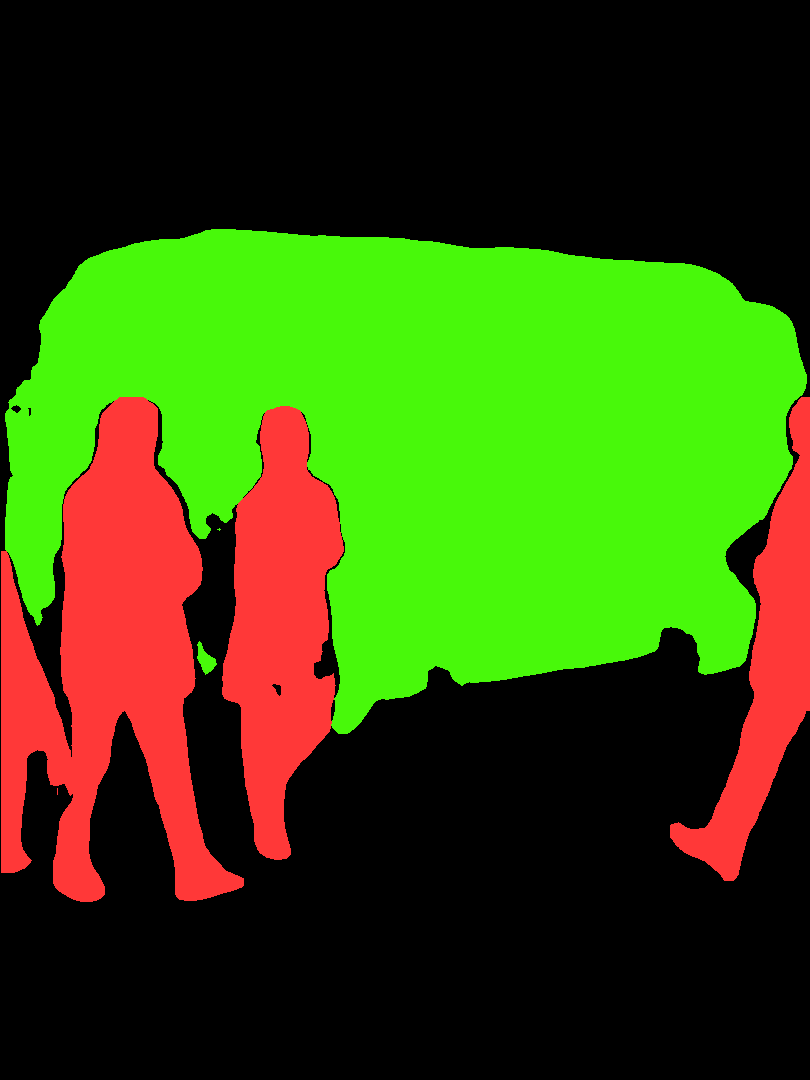

In [4]:
import numpy as np
lab = ys.imread(d / "conf0.25" / "mask_label.png")[:, :, 0]
for inst in res["segmentation"]["instances"]:
    area = int((lab == inst["mask_value"]).sum())
    print(f'#{inst["id"]} {inst["class_name"]:<8} JSON 면적={inst["mask_area_px"]:>7}  파일에서 센 면적={area:>7}  박스 안 마스크 비율={inst["mask_fill_ratio_in_box"]}')
display(Image(str(d / "conf0.25" / "mask_color.png"), width=400))

## 4. 내 사진 (공개·공유 동의한 사진만!)
`input/my_photo.jpg` 로 저장한 뒤 실행하세요. 파일이 없으면 건너뜁니다.

In [5]:
MY = ROOT / "input" / "my_photo.jpg"
if MY.exists():
    s = ys.process_image(MY, det_model, seg_model, [0.25, 0.50], 640, "cpu", OUT)
    print(json.dumps(s, ensure_ascii=False, indent=2))
    display(Image(str(OUT / MY.stem / "compare_thresholds.jpg")))
    display(Image(str(OUT / MY.stem / "conf0.25" / "panel.jpg")))
else:
    print("input/my_photo.jpg 가 아직 없습니다 — 처리하지 않았습니다.")

input/my_photo.jpg 가 아직 없습니다 — 처리하지 않았습니다.


## 5. 작은 화면: 사진 올리기 + 임계값 슬라이더
사진을 올리고 슬라이더를 움직이면 결과가 다시 그려집니다. (이 화면의 결과는 `outputs/yolo/upload/` 에 저장)

In [6]:
import ipywidgets as W, cv2, numpy as np
up = W.FileUpload(accept="image/*", multiple=False, description="사진 올리기")
sl = W.FloatSlider(value=0.25, min=0.05, max=0.95, step=0.05, description="conf")
outw = W.Output()
state = {"img": ys.imread(ROOT / "input" / "bus.jpg")}

def render(*_):
    with outw:
        outw.clear_output(wait=True)
        img = state["img"]
        dets, _ = ys.run_detection(det_model, img, sl.value, 640, "cpu")
        insts, lab, _ = ys.run_segmentation(seg_model, img, sl.value, 640, "cpu")
        panel = ys.side_by_side([img, ys.draw_boxes(img, dets), ys.overlay_masks(img, lab, insts)],
                                ["original", f"boxes conf {sl.value:.2f}", "masks"], height=360)
        p = OUT / "upload" / f"panel_conf{sl.value:.2f}.jpg"
        ys.imwrite(p, panel)
        display(Image(str(p)))
        for b in dets:
            print(f'#{b["id"]} {b["class_name"]} {b["score"]:.2f} {b["xyxy"]}')

def on_upload(change):
    v = up.value
    item = v[0] if isinstance(v, (list, tuple)) else list(v.values())[0]
    data = bytes(item["content"])
    state["img"] = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    render()

up.observe(on_upload, names="value")
sl.observe(render, names="value")
display(W.HBox([up, sl]), outw)
render()

Output()